In [1]:
import pandas, sklearn, matplotlib, joblib
print("pandas:", pandas.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("joblib:", joblib.__version__)

pandas: 2.3.2
scikit-learn: 1.7.2
matplotlib: 3.10.7
joblib: 1.5.2


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [13]:
df = pd.read_csv("spam.csv", encoding="latin-1")[["label", "message"]]
df.columns = ["label", "text"]
df.head()

,label,text
0,ham,"Hey, how are you?"
1,spam,Congratulations! You won a free iPhone. Claim ...
2,ham,Are you coming to college tomorrow?
3,spam,You have won a lottery worth 10 lakh rupees!
4,ham,Please send me today's notes.


In [14]:
print("Shape:", df.shape)
df["label"].value_counts(normalize=True)

Shape: (98, 2)


label
ham     0.5
spam    0.5
Name: proportion, dtype: float64

In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [16]:
df = df.drop_duplicates().reset_index(drop=True)
print("New shape:", df.shape)

New shape: (98, 2)


In [17]:
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
df.head()

,label,text,label_num
0,ham,"Hey, how are you?",0
1,spam,Congratulations! You won a free iPhone. Claim ...,1
2,ham,Are you coming to college tomorrow?,0
3,spam,You have won a lottery worth 10 lakh rupees!,1
4,ham,Please send me today's notes.,0


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["label_num"],
    test_size=0.2,
    random_state=42,
    stratify=df["label_num"],
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))

Train size: 78
Test size: 20


In [19]:
vectorizer = TfidfVectorizer(lowercase=True, stop_words="english")

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Train matrix shape:", X_train_vec.shape)
print("Test matrix shape:", X_test_vec.shape)

Train matrix shape: (78, 168)
Test matrix shape: (20, 168)


In [20]:
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))
print("Some words:", vectorizer.get_feature_names_out()[:20])

Vocabulary size: 168
Some words: ['10' 'account' 'activate' 'activity' 'address' 'apply' 'approval'
 'assignment' 'available' 'bank' 'birthday' 'blocked' 'bonus' 'book'
 'booked' 'brand' 'bring' 'buy' 'cancelled' 'card']


In [21]:
model = MultinomialNB()
model.fit(X_train_vec, y_train)
print("Model trained")

Model trained


In [22]:
sample = ["Congratulations! You won a free prize, click here to claim now",
          "Hey, are we still meeting for the project at 5?"]

sample_vec = vectorizer.transform(sample)
print(model.predict(sample_vec))

[1 0]


In [23]:
y_pred = model.predict(X_test_vec)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Accuracy: 0.95


In [24]:
print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

              precision    recall  f1-score   support

         ham       1.00      0.90      0.95        10
        spam       0.91      1.00      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20



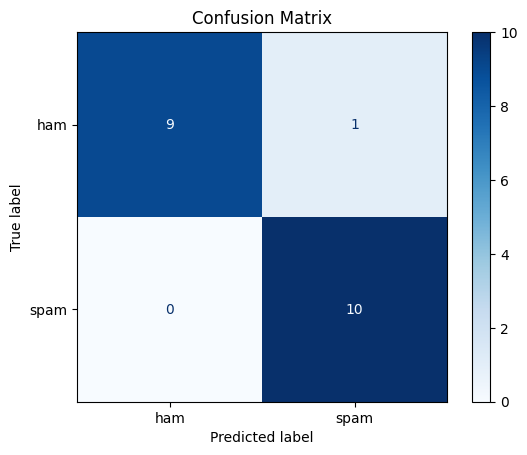

In [25]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [26]:
results = pd.DataFrame({"text": X_test, "actual": y_test, "predicted": y_pred})
missed_spam = results[(results["actual"] == 1) & (results["predicted"] == 0)]

print("Spam that got through:", len(missed_spam))
missed_spam.head(10)

Spam that got through: 0


,text,actual,predicted
